# 28 · A2A task lifecycle: input required, failure and cancel
Level L4 · Part 4 · professional · ~30 min · builds on 25, 27

## Goal
Follow an A2A task through its states. Three runs on one agent: a task that needs one more fact (input required) and continues when the caller
answers; a task whose work fails and ends as failed; and a task the caller cancels. The states are printed by name, so you can read each one.
No model call is made.

## Why it matters
A task can take a long time, need a person's answer, or break in the middle. A caller that waits for "an answer" and gets nothing does not know
whether the agent is working, waiting for it, or dead. The states say which, and each state has a next step for the caller.

| Without states | With states |
|---|---|
| The caller waits and cannot tell why | Working means wait; input-required means reply |
| A failure looks like silence | Failed is a final state the caller can act on |
| A cancel is a dropped connection | Canceled is a state the agent reports |

## The idea
The states are: **submitted** (the task exists), **working** (the agent is running it), **input-required** (the agent needs something from the
caller; the caller continues the same task with a new message), **completed**, **failed**, **canceled**, and **rejected** (the agent refuses the
task). Completed, failed, canceled and rejected are final. An input-required task waits for the caller, and continues when it is sent back.

## Picture
The first line of the next cell adds the topic folder to the import path, because the helper files live there. `graph_view.py` is this course's
drawing helper: `show_mermaid` draws a diagram written in Mermaid text.

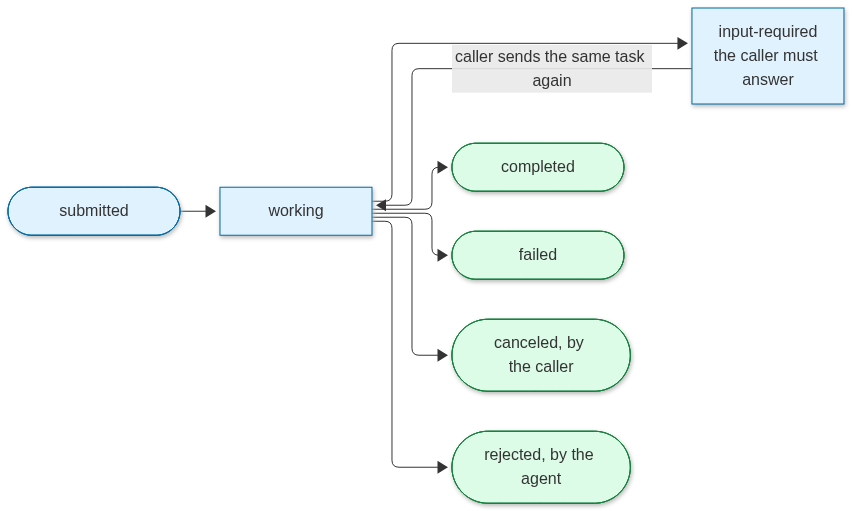

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py, a2a_server.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  S(["submitted"]) --> W["working"]
  W --> I["input-required<br/>the caller must answer"]
  I -->|caller sends the same task again| W
  W --> C(["completed"])
  W --> F(["failed"])
  W --> X(["canceled, by the caller"])
  W --> R(["rejected, by the agent"])
  classDef code fill:#e0f2fe,stroke:#0369a1
  classDef final fill:#dcfce7,stroke:#15803d
  class S,W,I code
  class C,F,X,R final
""")

## Step by step

**Step 1 · an agent whose tasks can need input, fail or be canceled (no call).** The executor reads the message. If it has no order number, the
task goes to input-required and waits. If the message says `break`, the work fails on purpose, so the failed state is shown. A cancel stops the
task before it completes. Each branch is a few lines, and each ends with one state. `a2a_server.py` is this topic's local A2A server helper:
`serve` starts an agent on a free local port, `stop` shuts it down, and `send_text` sends one message and returns the events the agent sent back.

In [2]:
import json
from pathlib import Path

from a2a.helpers import get_message_text, new_task_from_user_message, new_text_part, new_text_message
from a2a.server.agent_execution import AgentExecutor
from a2a.server.tasks import TaskUpdater
from a2a.types import a2a_pb2
from a2a_server import serve, stop, send_text

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]
print("orders the agent can look up:", len(ORDERS))

orders the agent can look up: 12


The executor is the agent's own code. The server calls its `execute` method for each message the caller sends.

In [3]:
class LifecycleExecutor(AgentExecutor):
    async def execute(self, context, event_queue):
        task = context.current_task or new_task_from_user_message(context.message)
        if not context.current_task:
            await event_queue.enqueue_event(task)
        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work()
        text = get_message_text(context.message)
        if "break" in text.lower():
            await updater.failed(new_text_message("the order service did not respond"))  # a final state
            return
        digits = [w.strip("?.,") for w in text.split() if w.strip("?.,").isdigit()]
        if not digits:
            await updater.requires_input(new_text_message("Which order number is it? Four digits, from the confirmation email."))
            return  # the task waits here, in input-required, until the caller sends the number
        row = ORDERS.get(digits[0], {"status": "not found", "days_late": 0})
        await updater.add_artifact([new_text_part(f"Order {digits[0]} is {row['status']}.")], name="answer")
        await updater.complete()

    async def cancel(self, context, event_queue):
        task = context.current_task
        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.cancel(new_text_message("the caller canceled the task"))

Now start the agent. It gets a local address, and the caller reads its card from there.

In [4]:
base, server = serve("lifecycle-agent", "Order status, with its states.",
                     [("order_status", "Order status", "Status of one order.")], LifecycleExecutor())
print("agent running at", base)

agent running at http://127.0.0.1:39801


**Step 2 · a task that needs input, then continues (no call).** The first message has no order number, so the task stops in input-required.
The caller sends the number with the same task id. The task continues to completed. The states are read from each event.

In [5]:
def states(events) -> list[str]:
    return [a2a_pb2.TaskState.Name(e.task.status.state) for e in events if e.HasField("task")]


first = await send_text(base, "Where is my order?")
task_id = next(e.task.id for e in first if e.HasField("task"))
print("first message:", states(first))
prompt = [e.task.status.message.parts[0].text for e in first if e.HasField("task") and e.task.status.HasField("message")]
print("the agent asks:", prompt[-1] if prompt else "(no prompt found)")

second = await send_text(base, "It is order 1003.", task_id=task_id)
print("second message, same task:", states(second))
print("artifact:", [a.parts[0].text for e in second if e.HasField("task") for a in e.task.artifacts])

first message: ['TASK_STATE_INPUT_REQUIRED']
the agent asks: Which order number is it? Four digits, from the confirmation email.
second message, same task: ['TASK_STATE_COMPLETED']
artifact: ['Order 1003 is lost.']


**Step 3 · a task that fails (no call).** A message that makes the work fail ends the task in failed. The failed state is final: the caller reads
the reason and decides what to do, rather than waiting.

In [6]:
failed = await send_text(base, "Break the order 1003 check.")
print("failing task:", states(failed))
print("reason:", [e.task.status.message.parts[0].text for e in failed if e.HasField("task") and e.task.status.HasField("message")])

failing task: ['TASK_STATE_FAILED']
reason: ['the order service did not respond']


**Step 4 · a task the caller cancels (no call).** A task that waits in input-required can be canceled. The agent reports the canceled state; the
caller does not have to guess that the task died. The `cancel` method in the executor above runs on the agent when the caller's cancel request
arrives. The `request_cancel` function below is the caller's side of that request.

In [7]:
waiting = await send_text(base, "Where is my order?")
waiting_id = next(e.task.id for e in waiting if e.HasField("task"))
print("waiting task:", states(waiting))

from a2a.types import CancelTaskRequest
import httpx
from a2a.client import A2ACardResolver, create_client


async def request_cancel(task_id: str):
    async with httpx.AsyncClient() as http:
        card = await A2ACardResolver(http, base).get_agent_card()
        client = await create_client(card)
        result = await client.cancel_task(CancelTaskRequest(id=task_id))
        await client.close()
        return result


canceled = await request_cancel(waiting_id)
print("after cancel:", a2a_pb2.TaskState.Name(canceled.status.state))

waiting task: ['TASK_STATE_INPUT_REQUIRED']


after cancel: TASK_STATE_CANCELED


## At work
- Input-required is how an agent asks a person a question in the middle of a task. The UI shows the question and sends the answer as the next
  message of the same task → lesson 13 (approval gate) and lesson 14 (checkpoint).
- Failed is final, and the caller decides the next step: retry, escalate or tell the customer. A failure with no reason is a bug in the agent.
- Canceled should be honoured quickly, and the agent should release what it holds. A canceled refund must not still be paid → lesson 35.

## What just happened
- The first message gave `TASK_STATE_INPUT_REQUIRED`, and the agent asked for the four-digit order number.
- The same task, sent again with "It is order 1003.", gave `TASK_STATE_COMPLETED` and the artifact "Order 1003 is lost."
- The "break" message gave `TASK_STATE_FAILED`, with the reason "the order service did not respond".
- The waiting task gave `TASK_STATE_INPUT_REQUIRED`; after the cancel request it reported `TASK_STATE_CANCELED`.

## Common mistakes
Each mistake below is followed by a cell that shows the real error, then the fix.

1. **Reading the answer before the task is done.** Input-required is a pause: it is neither a failure nor an answer. The first reply has no
   artifact yet, so code that reads one fails.

In [8]:
try:
    answer = first[-1].task.artifacts[0].parts[0].text  # no artifact yet: the task is still waiting
except Exception as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])

IndexError → list index out of range


**Fix:** read the state first. Only a completed task has an answer; an input-required task asks the user and is sent again.

In [9]:
state = states(first)[-1]
if state == "TASK_STATE_COMPLETED":
    print("answer:", first[-1].task.artifacts[0].parts[0].text)
else:
    print("state:", state, "→ ask the user, then send the same task again")

state: TASK_STATE_INPUT_REQUIRED → ask the user, then send the same task again


2. **A task with no final state.** A caller that waits for a task which never reaches completed, failed, canceled or rejected waits forever.
   The cell below polls a state that never changes; the deadline is the only way out.

In [10]:
import asyncio


async def poll_until_final(state_name: str):
    while state_name not in {"TASK_STATE_COMPLETED", "TASK_STATE_FAILED", "TASK_STATE_CANCELED", "TASK_STATE_REJECTED"}:
        await asyncio.sleep(0.05)  # the state never changes here, so this loop never ends
    return state_name


try:
    await asyncio.wait_for(poll_until_final("TASK_STATE_INPUT_REQUIRED"), timeout=0.3)
except Exception as error:
    print(type(error).__name__, "→", (str(error).splitlines() or ["no final state after 0.3 s"])[0])

TimeoutError → no final state after 0.3 s


**Fix:** stop polling at a final state, and give the wait a deadline. A completed state returns at once.

In [11]:
print("returned at once:", await asyncio.wait_for(poll_until_final("TASK_STATE_COMPLETED"), timeout=0.3))

returned at once: TASK_STATE_COMPLETED


3. **Canceling a task that already ended.** A task in a final state cannot be canceled. The agent refuses, so the caller gets an error and not a
   silent success. The cell below sends a second cancel to the task canceled in Step 4.

In [12]:
try:
    await request_cancel(waiting_id)  # this task is already canceled, so it is final
except Exception as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])

TaskNotCancelableError → Task cannot be canceled


**Fix:** read the state first and cancel only a task that is still running. This cell also stops the agent.

In [13]:
print("state:", a2a_pb2.TaskState.Name(canceled.status.state), "→ nothing left to cancel")
stop(server)

state: TASK_STATE_CANCELED → nothing left to cancel


## Try it
Write `is_final(state_name)` that returns `True` for `TASK_STATE_COMPLETED`, `TASK_STATE_FAILED`, `TASK_STATE_CANCELED` and `TASK_STATE_REJECTED`,
and `False` otherwise. Test it on `"TASK_STATE_WORKING"` and on `"TASK_STATE_FAILED"`. No model call is needed.

In [14]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [15]:
FINAL = {"TASK_STATE_COMPLETED", "TASK_STATE_FAILED", "TASK_STATE_CANCELED", "TASK_STATE_REJECTED"}


def is_final(state_name: str) -> bool:
    return state_name in FINAL


print(is_final("TASK_STATE_WORKING"), is_final("TASK_STATE_FAILED"))  # False True

False True


## Key terms
- **Input-required** — a task state in which the agent has paused and needs an answer; the caller sends it as the same task.
- **Final state** — completed, failed, canceled or rejected: a task in one of these does not change again.
- **Cancel** — the caller's request to stop a task; the agent answers with the canceled state.
- **Rejected** — the final state in which the agent refuses the task.

## Recap
- A task moves through named states; four of them are final.
- Input-required pauses the task until the caller sends the answer with the same task id.
- A failure and a cancel are states the agent reports, so the caller never waits for a task that has stopped.

**Interview:** "A long agent task needs a human's answer partway, and sometimes fails or is canceled. How does the caller know what to show?" Strong answer:
"Each state says what the caller does next: working means wait, input-required means ask the user and send the answer as the same task, and failed or
canceled are final, so the caller stops and reports them."